# 用 SymPy 自动生成代码

SymPy 能把式子输出成各种形式，不只是 LaTeX、MathML 这类用于显示的形式，还能转换成 Python、C、Fortran 的代码；那些符号形式的式子也可以变成做数值计算的函数。

- 用 `lambdify()` 把式子变成 Python 的函数
- 用 `autowrap()` 做成 C 的扩展模块
- 用 `codegen()` 写出 C 的源码

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
from sympy import *
import sympy

## 用 `lambdify` 把式子变成函数

`lambdify()` 把式子变成做数值计算的函数。作为例子，先用 `solve()` 把二次方程的解以符号形式求出来。

In [2]:
a, b, c, x = symbols("a, b, c, x", real=True)
quadratic_roots = solve(a * x**2 + b * x + c, x)  # 二次方程的解
quadratic_roots

[(-b - sqrt(-4*a*c + b**2))/(2*a), (-b + sqrt(-4*a*c + b**2))/(2*a)]

再用 `lambdify()` 把式子变成函数，调用它就得到数值解：第 1 个参数是要作为函数参数的那些符号的列表，第 2 个参数是它要返回的式子。如果把列表或元组放进去，就能一次返回多个式子的值。

In [3]:
roots_numpy = lambdify([a, b, c], quadratic_roots)  # 把式子变成函数
roots_numpy(2, -3, 1)

[np.float64(0.5), np.float64(1.0)]

指定 `modules` 就能决定式子里用到的数学函数取自哪个模块，默认按下面的顺序去找。

- 有 SciPy 时用 `["scipy", "numpy"]`
- 只有 NumPy 时用 `["numpy"]`
- 两者都没有时用 `["math", "mpmath", "sympy"]`

也就是说，只要能替换，就会把 SymPy 的函数换成 `scipy` 或 `numpy` 的函数。由于装了 NumPy，`sqrt` 就成了 `numpy.sqrt()`，参数也可以是数组；下面的例子一次解三个二次方程。

In [4]:
roots_numpy(np.array([2, 1, 0.5]), -3, 1)

[array([0.5       , 0.38196601, 0.35424869]),
 array([1.        , 2.61803399, 5.64575131])]

这里查看生成的函数源码，以及其中的 `sqrt` 指向什么，从而知道 `lambdify()` 到底做了什么函数出来。

In [5]:
import inspect

print(inspect.getsource(roots_numpy))  # 显示函数的源码
print(
    roots_numpy.__globals__["sqrt"] is np.sqrt
)  # 取得函数内部使用的 sqrt 的引用

def _lambdifygenerated(a, b, c):
    return [(1/2)*(-b - sqrt(-4*a*c + b**2))/a, (1/2)*(-b + sqrt(-4*a*c + b**2))/a]

True


把 `cmath` 传给 `modules`，`sqrt()` 就会返回复数。

In [6]:
import cmath

roots_cmath = lambdify((a, b, c), quadratic_roots, modules=cmath)  # 使用 cmath 的 sqrt
roots_cmath(2, 2, 1)

[(-0.5-0.5j), (-0.5+0.5j)]

源码与 `roots_numpy()` 相同，区别只是 `sqrt` 换成了 `cmath` 里的那个。

In [7]:
print(inspect.getsource(roots_cmath))
print(roots_cmath.__globals__["sqrt"].__module__)

def _lambdifygenerated(a, b, c):
    return [(1/2)*(-b - sqrt(-4*a*c + b**2))/a, (1/2)*(-b + sqrt(-4*a*c + b**2))/a]

cmath


看源码会发现同样的计算被算了两遍。把 `cse=True` 设上，它会找出公共的子表达式放进局部变量，从而减少计算次数。

In [8]:
roots_cse = lambdify((a, b, c), quadratic_roots, cse=True)  # 合并公共子表达式
print(inspect.getsource(roots_cse))

def _lambdifygenerated(a, b, c):
    x0 = sqrt(-4*a*c + b**2)
    x1 = (1/2)/a
    return [x1*(-b - x0), x1*(-b + x0)]



`sqrt(-4*a*c + b**2)` 被放进 `x0`、`(1/2)/a` 被放进 `x1`，于是同样的计算只做一次就够了。

把字典传给 `modules`，就可以自己决定要调用的函数：下面的代码里把 `sqrt` 指定成 `my_sqrt`，调用时由 `my_sqrt` 计算，并在这个过程中输出一条信息。

`modules` 也可以给列表，越靠前的优先级越高。

In [9]:
def my_sqrt(x):
    print(f"call my_sqrt with {x}")
    return x**0.5


roots_myfunc = lambdify(
    (a, b, c), quadratic_roots, modules=[{"sqrt": my_sqrt}, "numpy"], cse=True
)
roots_myfunc(2, -3, 1)

call my_sqrt with 1


[0.5, 1.0]

In [10]:
roots_myfunc.__globals__["sqrt"]

<function __main__.my_sqrt(x)>

`lambdify()` 对某些函数会在内部做特殊处理，因此有时没法用 `modules` 替换掉。遇到这种情况，先用式子的 `replace()` 把函数换成别的，再生成代码。

下面的例子为了让 $\min (2 \sin(t), 1)$ 的代码能处理数组，把 `Min()` 换成 `numpy.amin()`。生成出来的代码里 `Min()` 确实变成了 `amin()`，但只要 `t` 是数组就会抛异常。

In [11]:
t = symbols("t", real=True)
expr = Min(2 * sin(t), 1)  # 无法处理数组的式子

f1 = lambdify([t], expr, modules="numpy")
print(inspect.getsource(f1))

x = np.linspace(0, 2 * np.pi, 10)
try:
    f1(x)
except ValueError as ex:
    print(ex)

def _lambdifygenerated(t):
    return reduce(minimum, [1, 2*sin(t)])



NumPy 的 `minimum()` 是 ufunc，所以能直接处理数组。要把 `Min()` 换成 `minimum()`，就自己定义一个 SymPy 函数 `minimum`，再用 `replace()` 把 `Min` 换成它。

In [12]:
minimum = Function("minimum")
f2 = lambdify([t], expr.replace(Min, minimum), modules="numpy")
print(inspect.getsource(f2))
print(f2(x))

def _lambdifygenerated(t):
    return minimum(1, 2*sin(t))

[ 0.00000000e+00  1.00000000e+00  1.00000000e+00  1.00000000e+00
  6.84040287e-01 -6.84040287e-01 -1.73205081e+00 -1.96961551e+00
 -1.28557522e+00 -4.89858720e-16]


自己定义的函数名与实际做计算的函数名不一致时，用 `modules` 的字典把对应关系指定出来：生成的代码会调用 `myfunc()`，而在那个环境里 `myfunc` 就是 `np.minimum()`。

In [13]:
myfunc = Function("myfunc")
f2 = lambdify([t], expr.replace(Min, myfunc), modules=[{"myfunc": np.minimum}, "numpy"])
print(inspect.getsource(f2))
print(f2.__globals__["myfunc"])

def _lambdifygenerated(t):
    return myfunc(1, 2*sin(t))

<ufunc 'minimum'>


## 生成样条的代码

样条是用多项式拼接来表示光滑曲线的方法，用于插值和拟合：它把相邻的点光滑地连起来，同时调整得不要太偏离数据点。

下面的代码用 `UnivariateSpline` 对数据做光滑近似，其中 `s=1` 是平滑的强度。

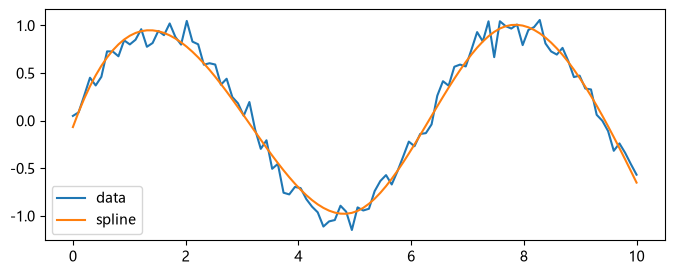

In [14]:
from scipy import interpolate

np.random.seed(42)
x_arr = np.linspace(0, 10, 100)
y_arr = np.sin(x_arr) + np.random.normal(scale=0.1, size=x_arr.shape[0])
spline = interpolate.UnivariateSpline(x_arr, y_arr, s=1)
plt.figure(figsize=(8, 3))
plt.plot(x_arr, y_arr, label="data")
plt.plot(x_arr, spline(x_arr), label="spline")
plt.legend();

`UnivariateSpline` 的内部属性 `_eval_args` 里放着计算样条所需的信息，也就是 `knots`、`coeffs`、`n` 这三个。

- `knots` 是节点的位置，区间就在这些位置分开。
- `coeffs` 是各区间多项式的系数。
- `n` 是节点的个数。

In [15]:
knots, coeffs, n = spline._eval_args
print(knots)
print(coeffs)
print(n)

[ 0.          0.          0.          0.          2.52525253  5.05050505
  7.57575758 10.         10.         10.         10.        ]
[-0.06742978  1.30989715  0.85005837 -2.17680281  2.11149148  0.3339333
 -0.65072061  0.          0.          0.          0.        ]
3


用 SymPy 的 `bspline_basis_set()` 可以把 B 样条的基函数算成式子：这里用上面的 `knots` 求出基函数，再画出来。

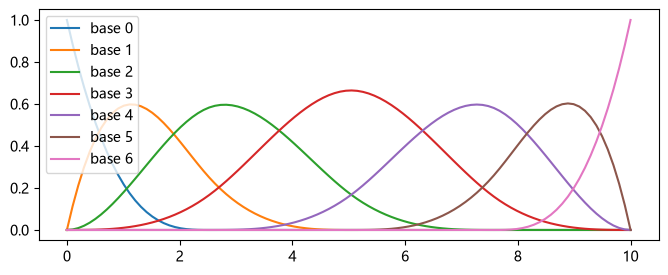

In [16]:
x = Symbol("x")
base_curves = bspline_basis_set(n, knots, x)  # B 样条的基函数

plt.figure(figsize=(8, 3))
for i, curve in enumerate(base_curves):
    plt.plot(x_arr, lambdify([x], curve)(x_arr), label=f"base {i}")
plt.legend();

每个基函数都是 `Piecewise()` 形式的分段函数。

In [17]:
base_curves[0]

Piecewise((-0.062099136*x**3 + 0.470448*x**2 - 1.188*x + 1.0, (x <= 2.52525252525253) & (x >= 0)), (0, True))

In [18]:
base_curves[1]

Piecewise((0.108673488*x**3 - 0.705672*x**2 + 1.188*x, (x <= 2.52525252525253) & (x >= 0)), (-0.015524784*x**3 + 0.235224*x**2 - 1.188*x + 2.0, (x >= 2.52525252525253) & (x <= 5.05050505050505)), (0, True))

把基函数乘上 `coeffs` 里的系数再相加，就得到样条的式子；下面的代码可以确认 `spline_expr` 的值与 `spline` 的值一致。

In [19]:
spline_expr = sum([v * curve for v, curve in zip(coeffs, base_curves)])  # 乘上系数再相加
spline_func = lambdify([x], spline_expr, cse=True)
np.allclose(spline(x_arr), spline_func(x_arr))

True

看生成的代码，会发现里面用了很多 NumPy 的 ufunc。

In [20]:
print(inspect.getsource(spline_func))

def _lambdifygenerated(x):
    x0 = x**2
    x1 = x**3
    x2 = logical_and.reduce((greater_equal(x, 7.57575757575758),less_equal(x, 10.0)))
    x3 = 1.188*x
    x4 = -0.470448*x0
    x5 = logical_and.reduce((less_equal(x, 2.52525252525253),greater_equal(x, 0)))
    x6 = -0.235224*x0
    x7 = logical_and.reduce((greater_equal(x, 2.52525252525253),less_equal(x, 5.05050505050505)))
    x8 = logical_and.reduce((greater_equal(x, 5.05050505050505),less_equal(x, 7.57575757575758)))
    x9 = 0.010349856*x1
    return -0.650720613486879*select([x2,True], [12.0849609375*x - 1.59521484375*x0 + 0.070189453125*x1 - 30.517578125,0], default=nan) - 0.0674297796339641*select([x5,True], [-0.062099136*x1 - x3 - x4 + 1.0,0], default=nan) + 1.30989714910869*select([x5,x7,True], [-0.705672*x0 + 0.108673488*x1 + x3,-0.015524784*x1 - x3 - x6 + 2.0,0], default=nan) + 0.33393329597181*select([x8,x2,True], [1.23698458975427*x - 0.244922948771345*x0 + 0.0161649146189088*x1 - 2.08246563931695,-22.4495388477457*x

把 `modules` 指定成 `"math"`，生成的代码就会变成一串 `if else`。

In [21]:
spline_func_scalar = lambdify([x], spline_expr, modules="math", cse=True)
print(inspect.getsource(spline_func_scalar))

def _lambdifygenerated(x):
    x0 = x**2
    x1 = x**3
    x2 = (x >= 7.57575757575758) and (x <= 10.0)
    x3 = 1.188*x
    x4 = -0.470448*x0
    x5 = (x >= 0) and (x <= 2.52525252525253)
    x6 = -0.235224*x0
    x7 = (x >= 2.52525252525253) and (x <= 5.05050505050505)
    x8 = (x >= 5.05050505050505) and (x <= 7.57575757575758)
    x9 = 0.010349856*x1
    return -0.650720613486879*((12.0849609375*x - 1.59521484375*x0 + 0.070189453125*x1 - 30.517578125) if x2 else (0)) - 0.0674297796339641*((-0.062099136*x1 - x3 - x4 + 1.0) if x5 else (0)) + 1.30989714910869*((-0.705672*x0 + 0.108673488*x1 + x3) if x5 else (-0.015524784*x1 - x3 - x6 + 2.0) if x7 else (0)) + 0.33393329597181*((1.23698458975427*x - 0.244922948771345*x0 + 0.0161649146189088*x1 - 2.08246563931695) if x8 else (-22.4495388477457*x + 2.88169814497865*x0 - 0.121406413506091*x1 + 57.731987485683) if x2 else (0)) + 0.850058366700105*((-0.056924208*x1 - x6) if x5 else (1.782*x + 0.036224496*x1 + x4 - 1.5) if x7 else (-1.782*x +

用 [numba 的 `vectorize`](numba-vectorize) 可以把标量用的函数编译成 ufunc；编译出来的 `spline_func_scalar_jit` 的值同样与 `spline` 一致。

In [22]:
from numba import vectorize, float64

spline_func_scalar_jit = vectorize([float64(float64)])(spline_func_scalar)
np.allclose(spline(x_arr), spline_func_scalar_jit(x_arr))

True

比较时间可以看出，`spline_func_scalar_jit()` 大约快 3 倍。

In [23]:
%timeit spline(x_arr)
%timeit spline_func_scalar_jit(x_arr)

16.7 μs ± 497 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


5.13 μs ± 141 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## 用 `autowrap()` 编译式子

`lambdify()` 把式子变成 Python 的函数，但对计算量大的式子来说，Python 的函数太慢了。这时就用 `autowrap()` 把式子变成 C 或 Fortran 代码，再编译成能从 Python 调用的扩展模块；编译的方式由 `backend` 选择。

* `'f2py'`：默认值，用 `f2py` 把 Fortran 程序做成扩展模块。
* `'cython'`：用 Cython 把 C 程序做成扩展模块。

这里用 `mingw32`，所以要建一个用于构建的文件夹，并把 `setup.cfg` 复制进去。

In [24]:
from pathlib import Path
import shutil

tmpdir = Path("./autowrap")
tmpdir.mkdir(parents=True, exist_ok=True)
shutil.copy("./setup.cfg", tmpdir);

把两个解放进 `Matrix` 之后，再用 `autowrap()` 变成函数；要注意这个函数只返回实数的解。

`autowrap()` 需要一个放临时文件的 `tempdir`，源码和扩展模块都会放在那里。`flags` 可以给编译命令加上选项，这里用 `-I` 指出 NumPy 头文件所在的位置。

In [25]:
from sympy.utilities.autowrap import autowrap

matrix_roots = Matrix(quadratic_roots)  # 把两个解放在一起
quadratic_roots_cython = autowrap(
    matrix_roots,
    args=[a, b, c],
    tempdir=tmpdir,
    backend="cython",
    flags=["-I" + np.get_include()],
)
quadratic_roots_cython(2, -3, 1)

array([[0.5],
       [1. ]])

同样把 `spline_expr` 也编译出来，并传入 `-Ofast` 得到优化过的二进制。

In [26]:
spline_cython = autowrap(
    spline_expr,
    args=[x],
    tempdir=tmpdir,
    backend="cython",
    flags=["-I" + np.get_include()],
    extra_compile_args=["-Ofast"],
)

In [27]:
np.allclose([spline_cython(v) for v in x_arr], spline(x_arr))

True

`spline_cython()` 一次只能算一个值，用 Python 循环反复调用太慢，所以用 `ufuncify()` 把式子做成 ufunc。

In [28]:
from sympy.utilities.autowrap import ufuncify

spline_cython_ufunc = ufuncify(
    [x],
    spline_expr,
    backend="cython",
    tempdir=tmpdir,
    flags=["-I" + np.get_include()],
    extra_compile_args=["-Ofast"],
)

先确认数值是否正确。

In [29]:
np.allclose(spline_cython_ufunc(x_arr), spline(x_arr))

True

再测一下计算速度，可以看到它比 Numba 的版本还快。

In [30]:
%timeit spline_cython_ufunc(x_arr)

1.48 μs ± 71.3 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


## 用 codegen 写出源码

`codegen()` 把式子变成源码：第 1 个参数是(函数名, 式子)这样的元组，或者这种元组的列表；`language` 决定语言、`prefix` 决定文件名。它返回两个元组，分别是源码文件与头文件的名字和内容。如果式子是 `Matrix`，输出时就用数组把各个元素放进去。

:::{note}
`language` 还可以取 `"octave"`、`"julia"` 等值，想看有哪些可选项就查文档。生成的源码里，函数名与 `prefix` 都由参数直接决定，所以改这两个参数就能控制输出文件的名字。
:::

In [31]:
from sympy.utilities.codegen import codegen

(c_name, c_code), (h_name, c_header) = codegen(
    [
        ("root0", quadratic_roots[0]),
        ("root1", quadratic_roots[1]),
        ("roots", matrix_roots),
    ],
    language="C",
    prefix="quadratic_roots",
    header=False,
)
print(h_name)
print("-" * 40)
print(c_header)
print()
print(c_name)
print("-" * 40)
print(c_code)

quadratic_roots.h
----------------------------------------

#ifndef PROJECT__QUADRATIC_ROOTS__H
#define PROJECT__QUADRATIC_ROOTS__H

double root0(double a, double b, double c);
double root1(double a, double b, double c);
void roots(double a, double b, double c, double *out_1899966207123195927);

#endif



quadratic_roots.c
----------------------------------------
#include "quadratic_roots.h"
#include <math.h>

double root0(double a, double b, double c) {

   double root0_result;
   root0_result = (1.0/2.0)*(-b - sqrt(-4*a*c + pow(b, 2)))/a;
   return root0_result;

}

double root1(double a, double b, double c) {

   double root1_result;
   root1_result = (1.0/2.0)*(-b + sqrt(-4*a*c + pow(b, 2)))/a;
   return root1_result;

}

void roots(double a, double b, double c, double *out_1899966207123195927) {

   out_1899966207123195927[0] = (1.0/2.0)*(-b - sqrt(-4*a*c + pow(b, 2)))/a;
   out_1899966207123195927[1] = (1.0/2.0)*(-b + sqrt(-4*a*c + pow(b, 2)))/a;

}



用 `ccode()` 和 `fcode()` 也可以把式子直接输出成 C 与 Fortran 的表达式。

In [32]:
print(ccode(matrix_roots, assign_to="y"))

y[0] = (1.0/2.0)*(-b - sqrt(-4*a*c + pow(b, 2)))/a;
y[1] = (1.0/2.0)*(-b + sqrt(-4*a*c + pow(b, 2)))/a;


想合并公共子表达式时，就直接用 `CCodeGen`：用 `cse=True` 构造出来的对象会带着 cse 来生成代码。

In [33]:
from sympy.utilities.codegen import CCodeGen

gen = CCodeGen("spline", cse=True)
r1 = gen.routine("spline_func", spline_expr, [x])
for filename, code in gen.write([r1], "spline"):
    print(filename)
    print(code)

spline.c
/******************************************************************************
 *                      Code generated with SymPy 1.14.0                      *
 *                                                                            *
 *              See http://www.sympy.org/ for more information.               *
 *                                                                            *
 *                       This file is part of 'spline'                        *
 ******************************************************************************/
#include "spline.h"
#include <math.h>

double spline_func(double x) {
   const double x0 = pow(x, 2);
   const double x1 = pow(x, 3);
   const double x2 = x >= 7.5757575757575752 && x <= 10.0;
   const double x3 = 1.1880000000000002*x;
   const double x4 = -0.47044800000000003*x0;
   const double x5 = x >= 0 && x <= 2.5252525252525251;
   const double x6 = -0.23522400000000002*x0;
   const double x7 = x >= 2.5252525252525251 &

## 小结

* `lambdify()` 能把式子变成做数值计算的函数，用 `modules` 选它要用的函数。
* `cse=True` 会把公共的子表达式合并起来，减少计算量。
* 式子里含有 `Min()` 这种特殊函数时，先用 `replace()` 换掉再生成代码。
* 样条可以从 `_eval_args` 里取出节点与系数，再用 `bspline_basis_set()` 变成式子。
* 用 `autowrap()` 编译成 C 的扩展模块比 `lambdify()` 快，用 `ufuncify()` 则能直接接收数组。
* `codegen()` 可以写出 C 或 Fortran 的源码。